## 01 — Exploratory Data Analysis: VisDrone2019-VID
Мета: до навчання моделей з'ясувати, які саме складнощі є в даних і які налаштування варто потім перевірити експериментально.

З опису competition 
- train: 56 clips / 24 201 frames; val: 7 clips / 2 846 frames; test: 48 clips / 3 811 frames, without annotations.
- 8 classes: person, bicycle, car, van, truck, tricycle, bus, motor.
- COCO annotations_coco.json: координати bbox = [x, y, width, height] у пікселях, category_id = 1…8 (YOLO і submission: 0…7).
- Ignored regions: iscrowd=1, це don't-care ділянки;

## 0. Setup 
`ROOT` — відомий шлях до competition; <br>
`FIG_DIR` — папка з графіками в доступному для запису


In [7]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.patches import Rectangle
from IPython.display import display

In [9]:
ROOT = Path('/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026')
FIG_DIR = Path('/kaggle/working/eda_figures')
SAVE_FIGURES = True

CLASS_NAMES = {
    1: 'person', 2: 'bicycle', 3: 'car', 4: 'van',
    5: 'truck', 6: 'tricycle', 7: 'bus', 8: 'motor'
}
CLASS_ORDER = list(CLASS_NAMES.values())

In [10]:
pd.set_option('display.max_columns', 30)

def finish_plot(filename):
    plt.tight_layout()
    if SAVE_FIGURES:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        plt.savefig(FIG_DIR / filename, dpi=180, bbox_inches='tight')
    plt.show()

print('Data:', ROOT)
print('Figures:', FIG_DIR, '| saving:', SAVE_FIGURES)

Data: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026
Figures: /kaggle/working/eda_figures | saving: True


## 1. COCO annotations
Використовуємо: `train/annotations_coco.json` і `val/annotations_coco.json`.

У COCO є images — по одному запису на кадр і annotations — по одному запису на bounding box або ignored region.

Перетворюємо JSON на дві таблиці: `images_df` (кадри, clip, frame_id, ширина/висота) і `annotations_df` (координати [x, y, w, h] у пікселях, category_id, iscrowd, occlusion, track_id). Додаємо `image_uid = split:id`, щоб однакові числові ID у train/val не змішались. У COCO `category_id = 1…8`, у YOLO та `submission = 0…7`.


In [11]:
def read_coco(split):
    with (ROOT / split / 'annotations_coco.json').open(encoding='utf-8') as f:
        coco = json.load(f)

    images = pd.DataFrame(coco['images'])
    images['image_uid'] = split + ':' + images['id'].astype(str)
    images['original_image_id'] = images['id'].astype(str)
    images['split'] = split
    images['clip'] = images['file_name'].map(lambda s: Path(str(s).replace('\\', '/')).parent.name)
    if 'frame_id' not in images:
        images['frame_id'] = np.nan
    images = images[['image_uid', 'original_image_id', 'split', 'clip', 'frame_id',
                     'file_name', 'width', 'height']].copy()

    ann = pd.DataFrame(coco['annotations'])
    ann['image_uid'] = split + ':' + ann['image_id'].astype(str)
    for col, default in [('iscrowd', 0), ('occlusion', np.nan), ('truncation', np.nan), ('track_id', np.nan)]:
        if col not in ann.columns:
            ann[col] = default
    # COCO bbox = [x, y, w, h]
    coords = pd.DataFrame(ann['bbox'].map(
        lambda b: list(b) if isinstance(b, (list, tuple)) and len(b) == 4
                  else [np.nan] * 4
    ).tolist(), columns=['x', 'y', 'box_w', 'box_h'])
    ann = pd.concat([ann.drop(columns=['bbox']).reset_index(drop=True), coords], axis=1)
    ann = ann[['image_uid', 'category_id', 'iscrowd', 'x', 'y',
               'box_w', 'box_h', 'occlusion', 'truncation', 'track_id']]

    print(f'{split}: {len(images):,} frames; {len(ann):,} annotations; '
          f'{images["clip"].nunique()} clips')
    return images, ann

train_images, train_annotations = read_coco('train')
val_images, val_annotations = read_coco('val')
images_df = pd.concat([train_images, val_images], ignore_index=True)
annotations_df = pd.concat([train_annotations, val_annotations], ignore_index=True)

print('\nExample frames:')
display(images_df.head(3))
print('Example raw annotations (category_id is 1-based):')
display(annotations_df.head(3))

train: 24,201 frames; 1,616,260 annotations; 56 clips
val: 2,846 frames; 146,092 annotations; 7 clips

Example frames:


,image_uid,original_image_id,split,clip,frame_id,file_name,width,height
0,train:1,1,train,uav0000013_00000_v,1,images/uav0000013_00000_v/0000001.jpg,1344,756
1,train:2,2,train,uav0000013_00000_v,2,images/uav0000013_00000_v/0000002.jpg,1344,756
2,train:3,3,train,uav0000013_00000_v,3,images/uav0000013_00000_v/0000003.jpg,1344,756


Example raw annotations (category_id is 1-based):


,image_uid,category_id,iscrowd,x,y,box_w,box_h,occlusion,truncation,track_id
0,train:1,1,0,424,543,35,88,0.0,0.0,2.0
1,train:1,1,0,416,530,36,85,1.0,0.0,3.0
2,train:1,6,0,531,641,87,114,0.0,1.0,4.0


Завантажено 24 201 train-кадр (56 clips) і 2 846 val-кадрів (7 clips). 

Записи анотацій: 1 616 260 train і 146 092 val; *ці числа включають ignored і тому не є кількістю цільових об'єктів.*

### 1.1. Відокремлюємо цільові об'єкти від ignored regions
`iscrowd=1`- ignored regions, також некоректні bounding boxes можуть спотворити статистику розмірів.

Тому:
- `annotations_df` зберігає всі COCO-анотації для аудиту; `valid_bbox` перевіряє додатні розміри та межі кадру.
- `target_df` містить лише валідні annotations із `iscrowd=0` та класами 1–8. Для них рахуємо `area_px`, `relative_area = box_area` / `image_area`, `aspect_ratio` = `width`/`height`.
- `size_group`: COCO-пороги за площею в початкових пікселях.
- `frames_df` включає всі кадри, навіть із 0 цільових boxes;

In [12]:
annotations_df = annotations_df.merge(
    images_df[['image_uid', 'split', 'clip', 'width', 'height']],
    on='image_uid', how='left', validate='many_to_one'
)

for col in ['x', 'y', 'box_w', 'box_h']:
    annotations_df[col] = pd.to_numeric(annotations_df[col], errors='coerce')

b = annotations_df
b['valid_bbox'] = (
    np.isfinite(b[['x', 'y', 'box_w', 'box_h']]).all(axis=1)
    & b['box_w'].gt(0) & b['box_h'].gt(0)
    & b['x'].ge(0) & b['y'].ge(0)
    & (b['x'] + b['box_w']).le(b['width'] + 1e-3)
    & (b['y'] + b['box_h']).le(b['height'] + 1e-3)
)
b['is_target'] = b['iscrowd'].eq(0) & b['category_id'].isin(CLASS_NAMES)

target_df = b.loc[b['is_target'] & b['valid_bbox']].copy()
target_df['class_name'] = target_df['category_id'].map(CLASS_NAMES)
target_df['area_px'] = target_df['box_w'] * target_df['box_h']
target_df['relative_area'] = target_df['area_px'] / (target_df['width'] * target_df['height'])
target_df['aspect_ratio'] = target_df['box_w'] / target_df['box_h']
target_df['size_group'] = pd.cut(
    target_df['area_px'], [0, 32**2, 96**2, np.inf],
    labels=['small', 'medium', 'large'], right=False
)

object_counts = target_df.groupby('image_uid').size().rename('n_objects')
frames_df = images_df.join(object_counts, on='image_uid')
frames_df['n_objects'] = frames_df['n_objects'].fillna(0).astype(int)
frames_df['resolution'] = (frames_df['width'].astype(str) + '×'
                           + frames_df['height'].astype(str))

print('Valid target boxes:', f'{len(target_df):,}')
print('All labelled frames (including empty):', f'{len(frames_df):,}')
print('Known classes:', sorted(target_df['category_id'].dropna().unique()))

Valid target boxes: 1,219,648
All labelled frames (including empty): 27,047
Known classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


Після виключення `ignored`/`non-target`/`invalid` залишилося 1 219 648 валідних цільових boxes у 27 047 розмічених кадрах, усі 8 цільових COCO `category_id` присутні.

*відбір застосовується лише до статистики EDA*

## 2. Dataset overview 
Перевіряємо кількість кадрів, clips, валідних target boxes і типову щільність. Оскільки сусідні кадри одного відео дуже схожі, train і validation не повинні ділити той самий clip.


In [13]:
summary = frames_df.groupby('split').agg(
    n_frames=('image_uid', 'size'), n_clips=('clip', 'nunique'),
    avg_objects_per_frame=('n_objects', 'mean'),
    median_objects_per_frame=('n_objects', 'median'),
    empty_frames=('n_objects', lambda s: int((s == 0).sum()))
)
summary['n_objects'] = target_df.groupby('split').size()
summary['empty_frame_share_%'] = 100 * summary['empty_frames'] / summary['n_frames']
display(summary.round(2))

print('Train / validation sequences overlap:',
      set(train_images['clip']) & set(val_images['clip']))

,n_frames,n_clips,avg_objects_per_frame,median_objects_per_frame,empty_frames,n_objects,empty_frame_share_%
split,,,,,,,
train,24201,56,45.68,43.0,3,1105516,0.01
val,2846,7,40.10,37.0,0,114132,0.00


Train / validation sequences overlap: set()


Порожніх train-кадрів лише 3/24 201, у val — 0/2 846. Відео між train і val не повторюються, тож split коректний за ідентифікаторами clip. Нижча середня щільність val вказує на відмінності в наборі сцен, але не дозволяє прогнозувати якість моделі.

## 3. Class distribution
Клас із малою кількістю прикладів може мати слабшу оцінку.


Count of target objects:


split,train,val
class_name,,
person,328701,50312
bicycle,40255,6022
car,505301,31821
van,46940,6842
truck,30498,1359
tricycle,41349,5487
bus,9653,264
motor,102819,12025


Share within split (%):


split,train,val
class_name,,
person,29.73,44.08
bicycle,3.64,5.28
car,45.71,27.88
van,4.25,5.99
truck,2.76,1.19
tricycle,3.74,4.81
bus,0.87,0.23
motor,9.30,10.54


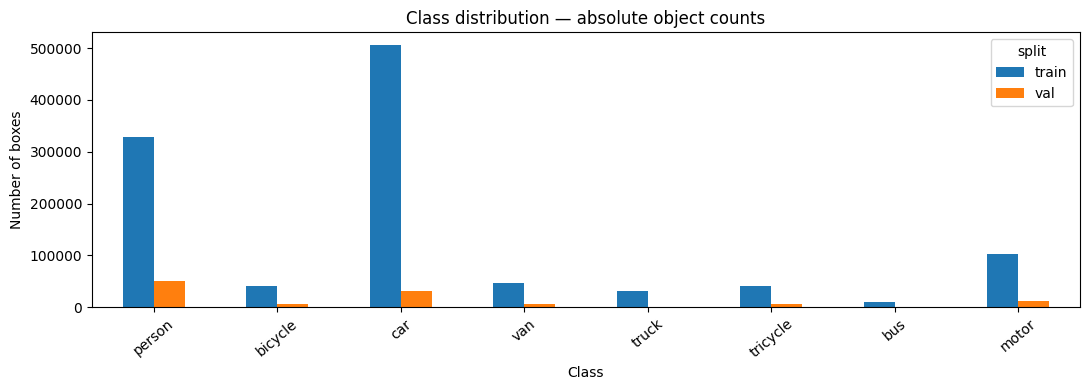

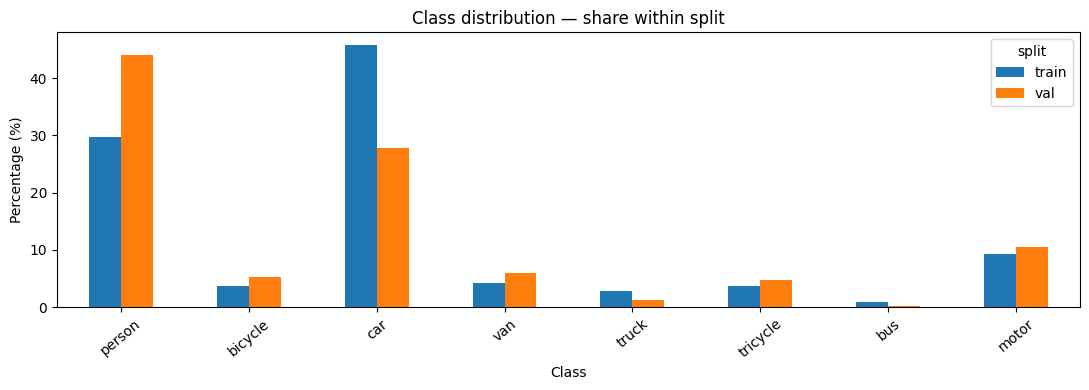

In [14]:
class_counts = pd.crosstab(target_df['class_name'], target_df['split'])
class_counts = class_counts.reindex(list(CLASS_NAMES.values()), fill_value=0)
class_share = (class_counts / class_counts.sum(axis=0) * 100).round(2)
print('Count of target objects:')
display(class_counts)
print('Share within split (%):')
display(class_share)

ax = class_counts.plot(kind='bar', figsize=(11, 4))
ax.set(title='Class distribution — absolute object counts', xlabel='Class', ylabel='Number of boxes')
ax.tick_params(axis='x', rotation=40)
finish_plot('class_distribution.png')

ax = class_share.plot(kind='bar', figsize=(11, 4))
ax.set(title='Class distribution — share within split', xlabel='Class', ylabel='Percentage (%)')
ax.tick_params(axis='x', rotation=40)
finish_plot('class_share.png')

У 'train' найбільші класи — car (45,71%) та person (29,73%); разом 75,44% цільових boxes. bus — (0,87%), найрідкісніший. motor —(9,30%).

Між Train та val shift: car зменшується, person зростає, bus — теж зменшується.

Для подальших експериментів: відстежувати per-class AP (bus, truck, bicycle) і перевірити class-aware sampling/augmentation лише якщо базові результати це виправдають. 

## 4. Object sizes

Для aerial object detection розміри bounding boxes впливають на вибір роздільності input, рівнів FPN, anchor scales та aspect ratios.

split,train,val
size_group,,
small,275347,21910
medium,702004,79357
large,128165,12865


split,train,val
bbox size,,
small,24.91,19.20
medium,63.50,69.53
large,11.59,11.27


boxes  median_width_px  median_height_px  median_area_px  \
split class_name                                                              
train bicycle      40255             43.0              43.0          1715.0   
      bus           9653            121.0             103.0         12870.0   
      car         505301             67.0              48.0          3250.0   
      motor       102819             38.0              43.0          1617.0   
      person      328701             25.0              50.0          1280.0   
      tricycle     41349             59.0              51.0          3009.0   
      truck        30498             79.0              68.0          5396.0   
      van          46940             55.0              46.0          2485.0   
val   bicycle       6022             66.0              64.0          4455.0   
      bus            264            138.0              64.0          8716.5   
      car          31821             77.0              53.0          4042.0   
      motor        12025             33.0              39.0          1274.0   
      person       50312             33.0              66.0          2233.0   
      tricycle      5487             49.0              53.0          2491.0   
      truck         1359            112.0              69.0          8970.0   
      van           6842             67.0              54.0          3770.0   

                  median_relative_area  share_small  
split class_name                                     
train bicycle                   0.0007       0.2441  
      bus                       0.0052       0.0414  
      car                       0.0014       0.1632  
      motor                     0.0007       0.3037  
      person                    0.0007       0.3949  
      tricycle                  0.0016       0.2103  
      truck                     0.0026       0.0939  
      van                       0.0012       0.2140  
val   bicycle                   0.0012       0.0286  
      bus                       0.0043       0.0000  
      car                       0.0013       0.0939  
      motor                     0.0008       0.4037  
      person                    0.0011       0.2474  
      tricycle                  0.0016       0.1852  
      truck                     0.0030       0.0280  
      van                       0.0017       0.0576

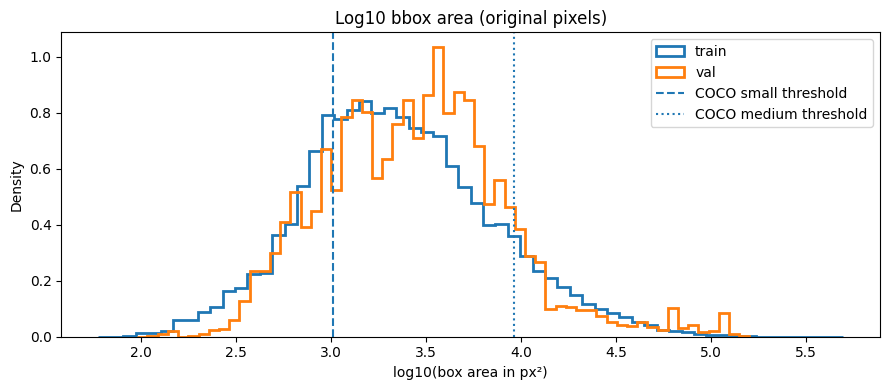

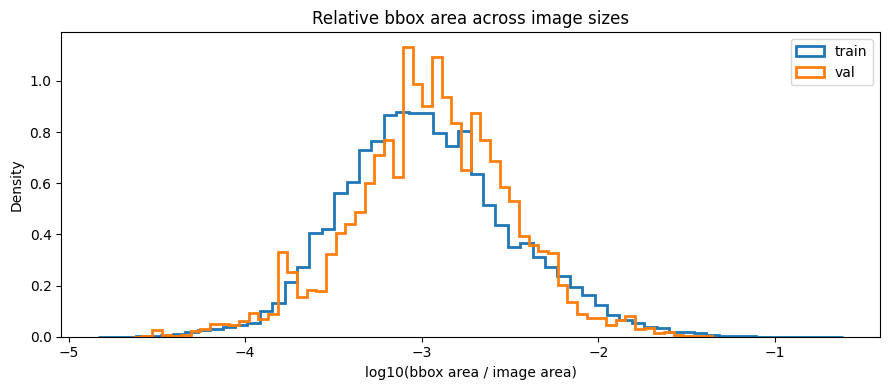

Train bbox width percentiles (px):


0.10     19.0
0.25     27.0
0.50     44.0
0.75     77.0
0.90    126.0
0.99    258.0
Name: box_w, dtype: float64

Train bbox aspect-ratio percentiles (w/h):


0.10    0.444444
0.25    0.590164
0.50    0.945652
0.75    1.456522
0.90    2.126761
Name: aspect_ratio, dtype: float64

Train: sizes by class


,boxes,median_width,median_height,small_pct,median_aspect_ratio
class_name,,,,,
person,328701,25.0,50.0,39.49,0.50
bicycle,40255,43.0,43.0,24.41,0.95
car,505301,67.0,48.0,16.32,1.25
van,46940,55.0,46.0,21.40,1.11
truck,30498,79.0,68.0,9.39,1.08
tricycle,41349,59.0,51.0,21.03,1.06
bus,9653,121.0,103.0,4.14,1.03
motor,102819,38.0,43.0,30.37,0.80


In [23]:
size_counts = pd.crosstab(target_df['size_group'], target_df['split'])
size_counts = size_counts.reindex(['small', 'medium', 'large'], fill_value=0)
display(size_counts)
display((size_counts.div(size_counts.sum(axis=0), axis=1) * 100).round(2).rename_axis('bbox size'))

size_stats = target_df.groupby(['split', 'class_name']).agg(
    boxes=('area_px', 'size'), median_width_px=('box_w', 'median'),
    median_height_px=('box_h', 'median'), median_area_px=('area_px', 'median'),
    median_relative_area=('relative_area', 'median'),
    share_small=('size_group', lambda s: (s == 'small').mean())
)
display(size_stats.round(4))

fig, ax = plt.subplots(figsize=(9, 4))
for split in ['train', 'val']:
    sub = target_df.loc[target_df['split'].eq(split), 'area_px']
    ax.hist(np.log10(sub), bins=60, histtype='step', linewidth=2,
            density=True, label=split)
ax.axvline(np.log10(32**2), linestyle='--', label='COCO small threshold')
ax.axvline(np.log10(96**2), linestyle=':', label='COCO medium threshold')
ax.set(title='Log10 bbox area (original pixels)', xlabel='log10(box area in px²)', ylabel='Density')
ax.legend()
finish_plot('box_area_hist.png')

fig, ax = plt.subplots(figsize=(9, 4))
for split in ['train', 'val']:
    values = target_df.loc[target_df['split'].eq(split), 'relative_area']
    ax.hist(np.log10(values), bins=60, density=True, histtype='step', linewidth=2, label=split)
ax.set(title='Relative bbox area across image sizes', xlabel='log10(bbox area / image area)', ylabel='Density')
ax.legend()
finish_plot('relative_box_area.png')

print('Train bbox width percentiles (px):')
display(target_df.loc[target_df['split'].eq('train'), 'box_w'].quantile([.1, .25, .5, .75, .9, .99]))
print('Train bbox aspect-ratio percentiles (w/h):')
display(target_df.loc[target_df['split'].eq('train'), 'aspect_ratio'].quantile([.1, .25, .5, .75, .9]))

# Median bbox width and small-object share by class, train only.
class_sizes = target_df[target_df['split'].eq('train')].groupby('class_name').agg(
    boxes=('area_px', 'size'),
    median_width=('box_w', 'median'),
    median_height=('box_h', 'median'),
    small_pct=('size_group', lambda s: 100 * (s == 'small').mean()),
    median_aspect_ratio=('aspect_ratio', 'median')
).reindex(CLASS_ORDER)
print('Train: sizes by class')
display(class_sizes.round(2))

Інтерпретація: класи відрізняються за розмірами та геометрією. Це дає підстави експериментально порівняти input resolution, anchor scales/aspect ratios та AP_small. Пороги COCO виміряні до resizing; фактичний розмір об'єкта на вході моделі може бути значно меншим.

### 4.1. Додаткове дослідження: як resizing змінить розміри об'єктів? (Запустити)

,short_target,long_limit,median_min_box_side_px,share_min_side_below_8_%,share_min_side_below_16_%,person_below_16_%,motor_below_16_%
0,640,1280,21.51,2.99,28.12,49.49,36.67
1,800,1333,25.20,1.71,19.52,36.77,25.33
2,1024,1600,30.25,0.96,12.35,26.84,15.23


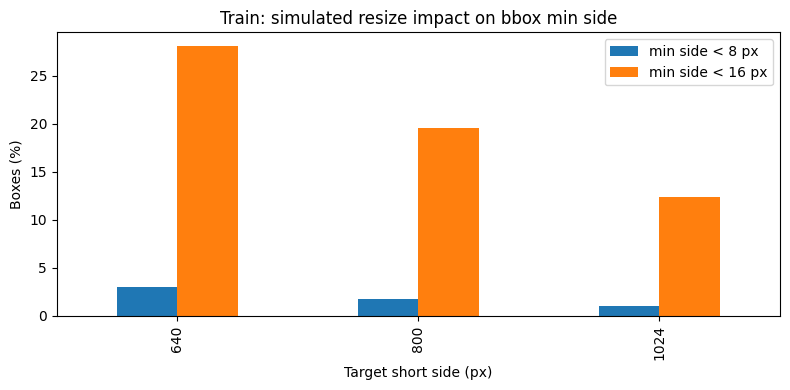

In [27]:
train_for_resize = target_df.loc[target_df['split'].eq('train')]
resize_candidates = [(640, 1280), (800, 1333), (1024, 1600)]
resize_rows = []
for short_side, long_limit in resize_candidates:
    W = train_for_resize['width'].to_numpy(dtype=float)
    H = train_for_resize['height'].to_numpy(dtype=float)
    scale = np.minimum(short_side / np.minimum(W, H),
                       long_limit / np.maximum(W, H))
    smaller_side = np.minimum(train_for_resize['box_w'].to_numpy(dtype=float),
                              train_for_resize['box_h'].to_numpy(dtype=float)) * scale
    resize_rows.append({
        'short_target': short_side, 'long_limit': long_limit,
        'median_min_box_side_px': float(np.median(smaller_side)),
        'share_min_side_below_8_%': 100 * float(np.mean(smaller_side < 8)),
        'share_min_side_below_16_%': 100 * float(np.mean(smaller_side < 16)),
        'person_below_16_%': 100 * float(np.mean(smaller_side[train_for_resize['class_name'].to_numpy() == 'person'] < 16)),
        'motor_below_16_%': 100 * float(np.mean(smaller_side[train_for_resize['class_name'].to_numpy() == 'motor'] < 16)),
    })
resize_impact = pd.DataFrame(resize_rows)
display(resize_impact.round(2))
ax = resize_impact.plot(x='short_target', y=['share_min_side_below_8_%', 'share_min_side_below_16_%'],
                        kind='bar', figsize=(8, 4))
ax.set(title='Train: simulated resize impact on bbox min side',
       xlabel='Target short side (px)', ylabel='Boxes (%)')
ax.legend(['min side < 8 px', 'min side < 16 px'])
finish_plot('resize_impact_simulation.png')

Висновок: зі збільшенням short side з 640 до 1024 px медіана меншої сторони bbox зростає, а частка boxes, у яких ця сторона менша за 16 px, зменшується. Отже, особливо для дрібних об'єктів зниження input resolution може бути ризикованим.

Для Faster R-CNN варто порівняти 800 та 1024 px за AP_small, загальним mAP, швидкістю й використанням VRAM. Це лише геометрична симуляція resizing, без навчання моделі: більша кількість пікселів не гарантує кращу детекцію.

## 5. Scene density
Дуже щільні сцени створюють ризик пропуску detections через обмеження кількості proposals/detections та пригнічення сусідніх boxes під час NMS. Кількість об'єктів не дорівнює кількості RPN proposals, але підказує, які обмеження треба експериментально перевірити.

,count,mean,std,min,10%,25%,50%,75%,90%,95%,99%,max
split,,,,,,,,,,,,
train,24201.0,45.68,31.56,0.0,9.0,22.0,43.0,57.00,92.0,118.0,142.00,180.0
val,2846.0,40.10,26.85,8.0,13.0,16.0,37.0,51.75,81.0,103.0,112.55,116.0


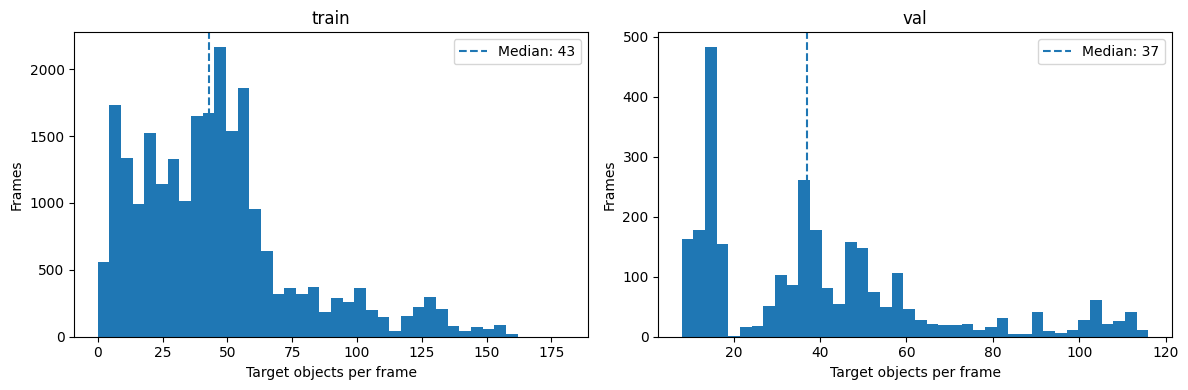

In [16]:
density_stats = frames_df.groupby('split')['n_objects'].describe(
    percentiles=[.1, .25, .5, .75, .9, .95, .99]
)
display(density_stats.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, split in zip(axes, ['train', 'val']):
    series = frames_df.loc[frames_df['split'].eq(split), 'n_objects']
    ax.hist(series, bins=40)
    ax.axvline(series.median(), linestyle='--', label=f'Median: {series.median():.0f}')
    ax.set(title=split, xlabel='Target objects per frame', ylabel='Frames')
    ax.legend()
finish_plot('objects_per_frame.png')

Типовий кадр значно менш щільний, ніж крайні випадки. Найскладніші за щільністю train-кадри майже вчетверо перевищують медіану. Це причина перевіряти ліміти RPN proposals, detections_per_img та NMS, але кількість об'єктів не є готовим значенням для цих параметрів — вони мають бути налаштовані за validation mAP та AP_small.

## 6. Sequence-level EDA
Кадри одного clip корельовані, а окремі відео можуть мати різну щільність, висоту камери, розміри та склад класів. Загальна середня статистика приховує ці відмінності.


Clips with highest average number of objects/frame:


,split,clip,n_frames,avg_objects,p90_objects,median_image_width,n_boxes,median_box_area,small_share
14,train,uav0000138_00000_v,213,142.962,154.0,2688.0,30451,2059.0,0.172
13,train,uav0000126_00001_v,412,132.218,145.0,2688.0,54474,2340.0,0.243
12,train,uav0000124_00944_v,398,124.568,132.0,2688.0,49578,2145.0,0.242
5,train,uav0000072_04488_v,85,110.376,123.6,1904.0,9382,2100.0,0.147
18,train,uav0000150_02310_v,348,108.885,147.0,2688.0,37892,3604.0,0.051
58,val,uav0000137_00458_v,233,103.382,113.0,2688.0,24088,5356.0,0.006
33,train,uav0000279_00001_v,547,95.347,120.0,1904.0,52155,1113.0,0.476
51,train,uav0000357_00920_v,691,91.891,101.0,1904.0,63497,1836.0,0.189
7,train,uav0000072_06432_v,97,89.948,109.4,1904.0,8725,1792.0,0.273
53,train,uav0000361_02323_v,219,85.804,93.0,1904.0,18791,2940.0,0.174


Clips with highest share of small objects:


,split,clip,n_frames,avg_objects,p90_objects,median_image_width,n_boxes,median_box_area,small_share
25,train,uav0000248_00001_v,677,47.495,59.0,1344.0,32154,899.0,0.731
22,train,uav0000239_12336_v,341,33.261,42.0,1344.0,11342,600.0,0.652
27,train,uav0000264_02760_v,616,19.073,22.0,1904.0,11749,961.0,0.545
32,train,uav0000278_00001_v,962,55.009,74.9,1360.0,52919,992.0,0.511
59,val,uav0000182_00000_v,363,48.680,78.0,1344.0,17671,1053.0,0.492
21,train,uav0000239_03720_v,680,23.019,32.0,1344.0,15653,1110.0,0.478
33,train,uav0000279_00001_v,547,95.347,120.0,1904.0,52155,1113.0,0.476
17,train,uav0000145_00000_v,307,11.238,16.0,2688.0,3450,1464.0,0.462
23,train,uav0000243_00001_v,768,22.943,34.0,1344.0,17620,1240.0,0.444
10,train,uav0000084_00000_v,516,54.083,59.0,1344.0,27907,1512.0,0.391


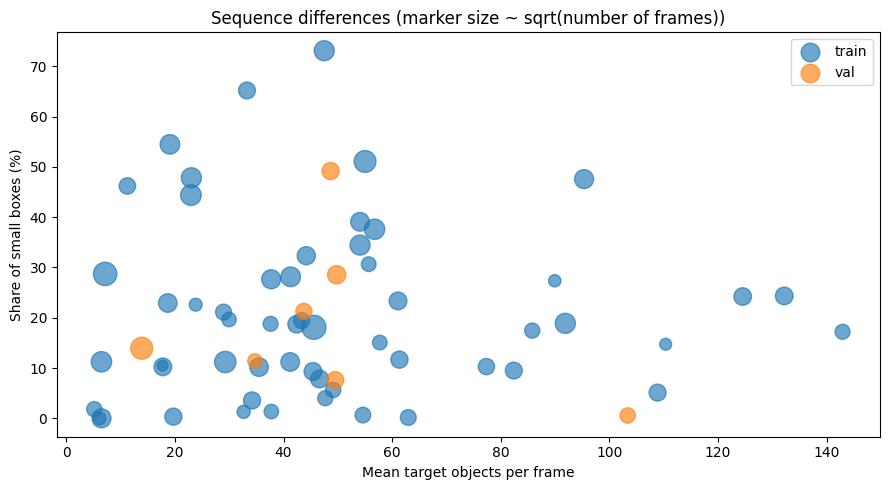

class_name,bicycle,bus,car,motor,person,tricycle,truck,van
clip,,,,,,,,
uav0000072_04488_v,0.6,0.0,4.4,2.5,87.5,3.0,1.1,0.9
uav0000072_06432_v,0.0,0.0,8.8,2.2,78.9,7.5,0.4,2.2
uav0000124_00944_v,6.3,0.2,67.3,4.3,19.3,0.0,0.0,2.6
uav0000126_00001_v,1.8,1.2,79.2,4.1,11.6,0.0,0.2,1.9
uav0000138_00000_v,9.7,2.1,41.3,3.3,40.9,0.0,0.0,2.6
uav0000150_02310_v,3.9,0.0,19.8,34.6,25.1,13.5,2.0,1.0
uav0000279_00001_v,1.3,0.0,65.2,2.4,22.2,4.4,2.9,1.5
uav0000357_00920_v,5.8,0.3,22.9,25.5,40.5,3.0,0.8,1.1


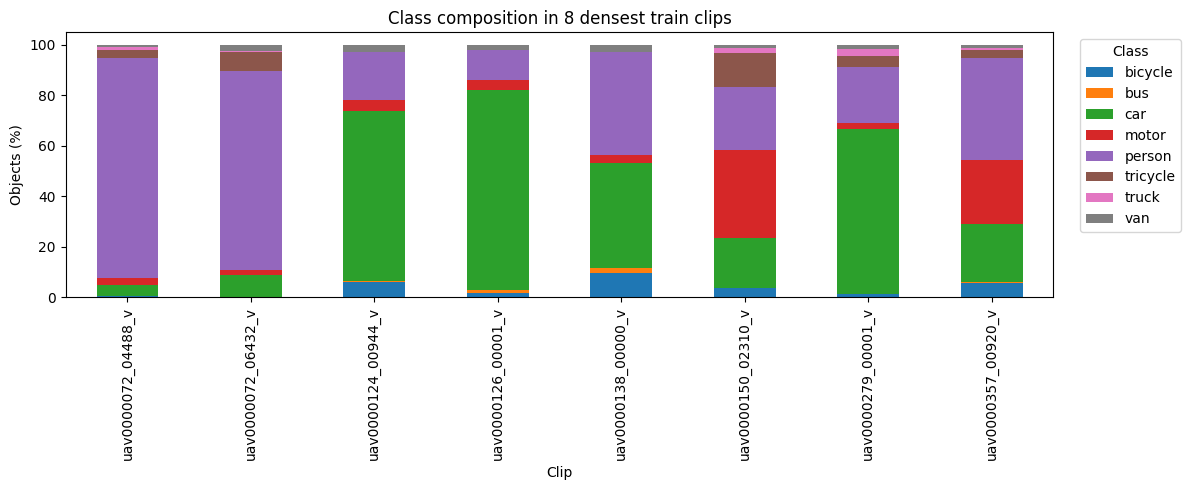

In [17]:
clip_frames = frames_df.groupby(['split', 'clip']).agg(
    n_frames=('image_uid', 'size'), avg_objects=('n_objects', 'mean'),
    p90_objects=('n_objects', lambda s: s.quantile(.9)),
    median_image_width=('width', 'median')
).reset_index()
clip_boxes = target_df.groupby(['split', 'clip']).agg(
    n_boxes=('area_px', 'size'), median_box_area=('area_px', 'median'),
    small_share=('size_group', lambda s: (s == 'small').mean()),
).reset_index()
clip_stats = clip_frames.merge(clip_boxes, on=['split', 'clip'], how='left')
clip_stats[['n_boxes', 'small_share']] = clip_stats[['n_boxes', 'small_share']].fillna(0)

print('Clips with highest average number of objects/frame:')
display(clip_stats.sort_values('avg_objects', ascending=False).head(12).round(3))
print('Clips with highest share of small objects:')
display(clip_stats.loc[clip_stats['n_boxes'].gt(0)]
        .sort_values('small_share', ascending=False).head(12).round(3))

fig, ax = plt.subplots(figsize=(9, 5))
for split, group in clip_stats.groupby('split'):
    ax.scatter(group['avg_objects'], group['small_share'] * 100,
               s=np.sqrt(group['n_frames']) * 8, alpha=.65, label=split)
ax.set(title='Sequence differences (marker size ~ sqrt(number of frames))',
       xlabel='Mean target objects per frame', ylabel='Share of small boxes (%)')
ax.legend()
finish_plot('sequence_density_vs_small.png')

# Class composition for a few densest train clips.
chosen = clip_stats.loc[clip_stats['split'].eq('train')].nlargest(8, 'avg_objects')['clip']
clip_class = pd.crosstab(
    target_df.loc[target_df['split'].eq('train') & target_df['clip'].isin(chosen), 'clip'],
    target_df.loc[target_df['split'].eq('train') & target_df['clip'].isin(chosen), 'class_name']
)
clip_class_pct = clip_class.div(clip_class.sum(axis=1), axis=0) * 100
display(clip_class_pct.round(1))
ax = clip_class_pct.plot(kind='bar', stacked=True, figsize=(12, 5))
ax.set(title='Class composition in 8 densest train clips', xlabel='Clip', ylabel='Objects (%)')
ax.legend(title='Class', bbox_to_anchor=(1.02, 1), loc='upper left')
finish_plot('class_composition_per_clip.png')

Є велика неоднорідність між clips. Наприклад, `uav0000138_00000_v` має 142,96 об'єктів/кадр у середньому; у `uav0000248_00001_v` 73,1% boxes класифікуються як small, але середня щільність лише 47,50. Отже, найбільша щільність не означає найвищу частку small.

Для наступних кроків: при аналізі помилок обирати різні clips, а не лише випадкові сусідні кадри. У cross-validation групувати за clip і перевіряти розподіл класів/щільності між folds.

## 7. Image resolutions
pixel size box залежить від оригінальної роздільності. Якщо зменшити 2688×1512 або 3840×2160 до стандартного model input, маленькі об'єкти можуть стати ще меншими. Для оцінювання координати predictions потрібно повернути у пікселі оригінального кадру.

,split,resolution,frames
2,train,1904×1071,12895
0,train,1344×756,5645
4,train,2688×1512,3505
1,train,1360×765,962
3,train,1920×1080,721
5,train,2720×1530,473
10,val,3840×2160,978
6,val,1344×756,827
7,val,1904×1071,459
9,val,2720×1530,349


resolution
1360×764     1474
1920×1080     991
1344×756      441
680×382       321
1904×1072     305
960×540       279
Name: test_frames, dtype: int64

Test clips: 48 | Test frames: 3811


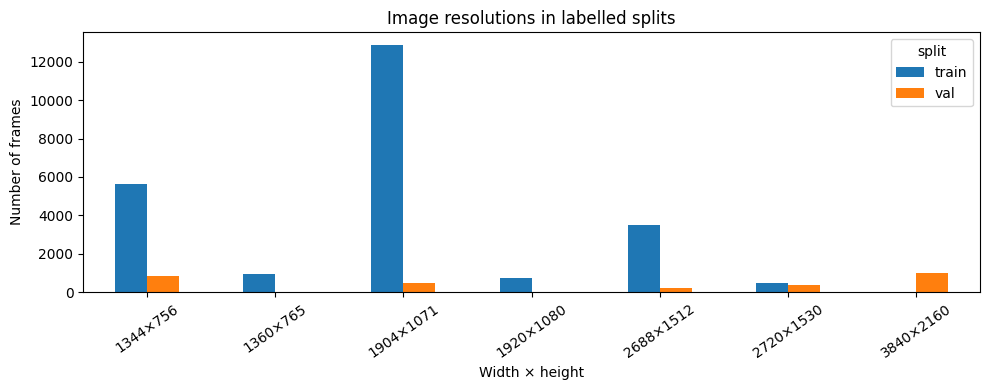

In [18]:
resolutions = frames_df.groupby(['split', 'resolution']).size().rename('frames').reset_index()
display(resolutions.sort_values(['split', 'frames'], ascending=[True, False]))

if (ROOT / 'test_images.csv').exists():
    test_meta = pd.read_csv(ROOT / 'test_images.csv')
    test_meta['resolution'] = test_meta['width'].astype(str) + '×' + test_meta['height'].astype(str)
    display(test_meta.groupby('resolution').size().rename('test_frames').sort_values(ascending=False))
    print('Test clips:', test_meta['clip'].nunique(), '| Test frames:', len(test_meta))
else:
    print('test_images.csv не знайдено, пропускаємо test-resolution EDA.')

fig, ax = plt.subplots(figsize=(10, 4))
resolution_plot = pd.crosstab(frames_df['resolution'], frames_df['split'])
resolution_plot.plot(kind='bar', ax=ax)
ax.set(title='Image resolutions in labelled splits', xlabel='Width × height', ylabel='Number of frames')
ax.tick_params(axis='x', rotation=35)
finish_plot('image_resolutions.png')

train/val/test не збігаються за розмірами зображень. Порівнювати лише піксельні bbox sizes між clips без урахування image width/height може бути оманливо; тому ми вже аналізуємо relative_area.


## 8. Annotation audit
`ignored regions` означають, що частина сцени не повністю розмічена. Навчати там «немає об'єктів» може створювати хибні negative examples. Аудит також шукає нецільові категорії, некоректні boxes і дублікати кадрів.


In [28]:
ignored = annotations_df['iscrowd'].eq(1)
non_target = ~annotations_df['category_id'].isin(CLASS_NAMES)
invalid_target = annotations_df['is_target'] & ~annotations_df['valid_bbox']

checks = pd.DataFrame({
    'metric': ['all annotations', 'ignored (iscrowd=1)',
               'non-target category IDs', 'invalid target boxes',
               'annotations with missing frame metadata',
               'duplicate (split, filename) frames'],
    'count': [len(annotations_df), int(ignored.sum()), int(non_target.sum()),
              int(invalid_target.sum()), int(annotations_df['width'].isna().sum()),
              int(images_df.duplicated(['split', 'file_name']).sum())]
})
display(checks)
print('Ignored regions by split:')
display(annotations_df.loc[ignored].groupby('split').size().rename('ignored_annotations'))
print('Ignored regions by clip (top 10):')
display(annotations_df.loc[ignored].groupby(['split', 'clip'])
        .size().sort_values(ascending=False).head(10).rename('ignored_annotations'))
if invalid_target.any():
    print('Sample invalid boxes for manual inspection:')
    display(annotations_df.loc[invalid_target].head(10))

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


,metric,count
0,all annotations,1762352
1,ignored (iscrowd=1),542704
2,non-target category IDs,0
3,invalid target boxes,0
4,annotations with missing frame metadata,0
5,"duplicate (split, filename) frames",0


Ignored regions by split:


split
train    510744
val       31960
Name: ignored_annotations, dtype: int64

Ignored regions by clip (top 10):


split  clip              
train  uav0000126_00001_v    53992
       uav0000278_00001_v    35784
       uav0000244_01440_v    33040
       uav0000357_00920_v    25832
       uav0000366_00001_v    20824
       uav0000323_01173_v    19968
       uav0000300_00000_v    19616
       uav0000084_00000_v    18240
       uav0000363_00001_v    18136
       uav0000295_02300_v    16136
Name: ignored_annotations, dtype: int64

Основні COCO-структури узгоджені, але ignored області суттєві. На наступному етапі preprocessing треба погодити don't-care обробку з evaluator;

### 8.1. Додаткове дослідження: на скількох кадрах є ignored regions? (Запустити)

In [29]:
# Include frames without ignored annotations when computing prevalence.
ignored_counts = (annotations_df.loc[annotations_df['iscrowd'].eq(1)]
                  .groupby('image_uid').size().rename('n_ignored'))
ignore_frames = frames_df[['image_uid','split','clip','n_objects']].join(
    ignored_counts, on='image_uid')
ignore_frames['n_ignored'] = ignore_frames['n_ignored'].fillna(0).astype(int)
ignore_prevalence = ignore_frames.groupby('split').agg(
    frames=('image_uid','size'),
    frames_with_ignored=('n_ignored',lambda s: int((s > 0).sum())),
    median_ignored_per_frame=('n_ignored','median'),
    p90_ignored_per_frame=('n_ignored',lambda s: s.quantile(.90))
)
ignore_prevalence['frames_with_ignored_%'] = (
    100 * ignore_prevalence['frames_with_ignored'] / ignore_prevalence['frames'])
display(ignore_prevalence.round(2))
per_clip_ignore = ignore_frames.groupby(['split','clip']).agg(
    frames=('image_uid','size'),
    frames_with_ignored=('n_ignored',lambda s: int((s > 0).sum())),
    avg_ignored=('n_ignored','mean')
)
per_clip_ignore['frames_with_ignored_%'] = (
    100 * per_clip_ignore['frames_with_ignored'] / per_clip_ignore['frames'])
print('Top clips by percentage of frames with ignored regions:')
display(per_clip_ignore.sort_values(['frames_with_ignored_%','avg_ignored'],ascending=False).head(10).round(2))

,frames,frames_with_ignored,median_ignored_per_frame,p90_ignored_per_frame,frames_with_ignored_%
split,,,,,
train,24201,18090,16.0,56.0,74.75
val,2846,1434,8.0,24.0,50.39


Top clips by percentage of frames with ignored regions:


frames  frames_with_ignored  avg_ignored  \
split clip                                                           
train uav0000126_00001_v     412                  412       131.05   
      uav0000366_00001_v     296                  296        70.35   
      uav0000138_00000_v     213                  213        64.30   
      uav0000140_01590_v     256                  256        53.69   
      uav0000361_02323_v     219                  219        48.00   
      uav0000323_01173_v     426                  426        46.87   
      uav0000295_02300_v     346                  346        46.64   
      uav0000143_02250_v     261                  261        46.13   
      uav0000244_01440_v     721                  721        45.83   
      uav0000363_00001_v     462                  462        39.26   

                          frames_with_ignored_%  
split clip                                       
train uav0000126_00001_v                  100.0  
      uav0000366_00001_v                  100.0  
      uav0000138_00000_v                  100.0  
      uav0000140_01590_v                  100.0  
      uav0000361_02323_v                  100.0  
      uav0000323_01173_v                  100.0  
      uav0000295_02300_v                  100.0  
      uav0000143_02250_v                  100.0  
      uav0000244_01440_v                  100.0  
      uav0000363_00001_v                  100.0

ignored regions — не поодинокий виняток, і відсутність обробки може створювати хибні background examples. Але ці числа характеризують кількість анотацій, а не площу масок і не частку нерозмічених пікселів. На етапі preprocessing потрібно перевірити, як ignored regions враховує конкретний evaluator, і правильно відобразити це в training pipeline.

## 9. Visual inspection
Таблиці не показують оклюзії, масштаб сцени, рух, перспективу й те, чи box знаходиться саме на потрібному об'єкті. Тут є sparse (0), typical (~median) і dense (~max) train кадри.


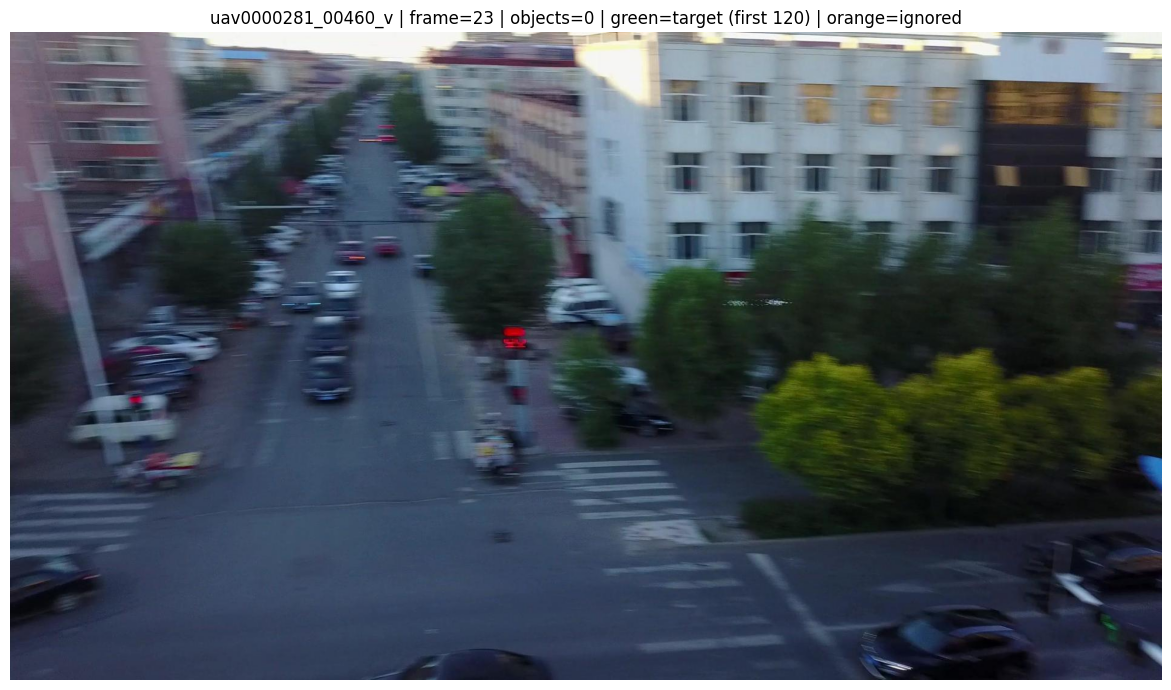

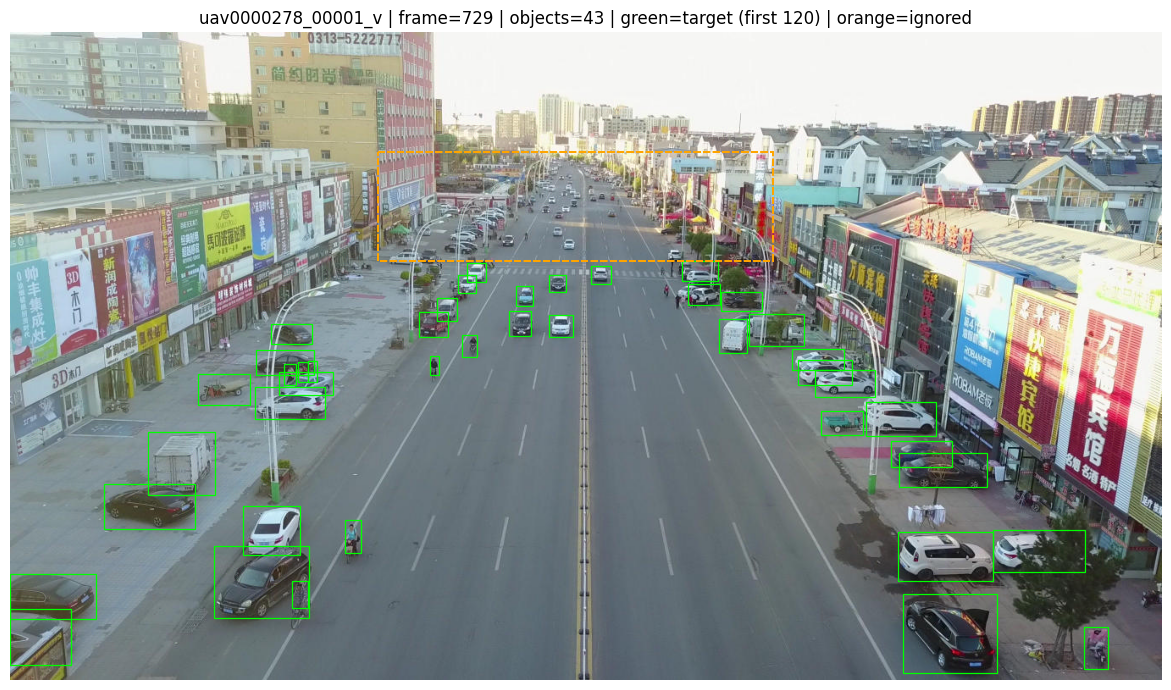

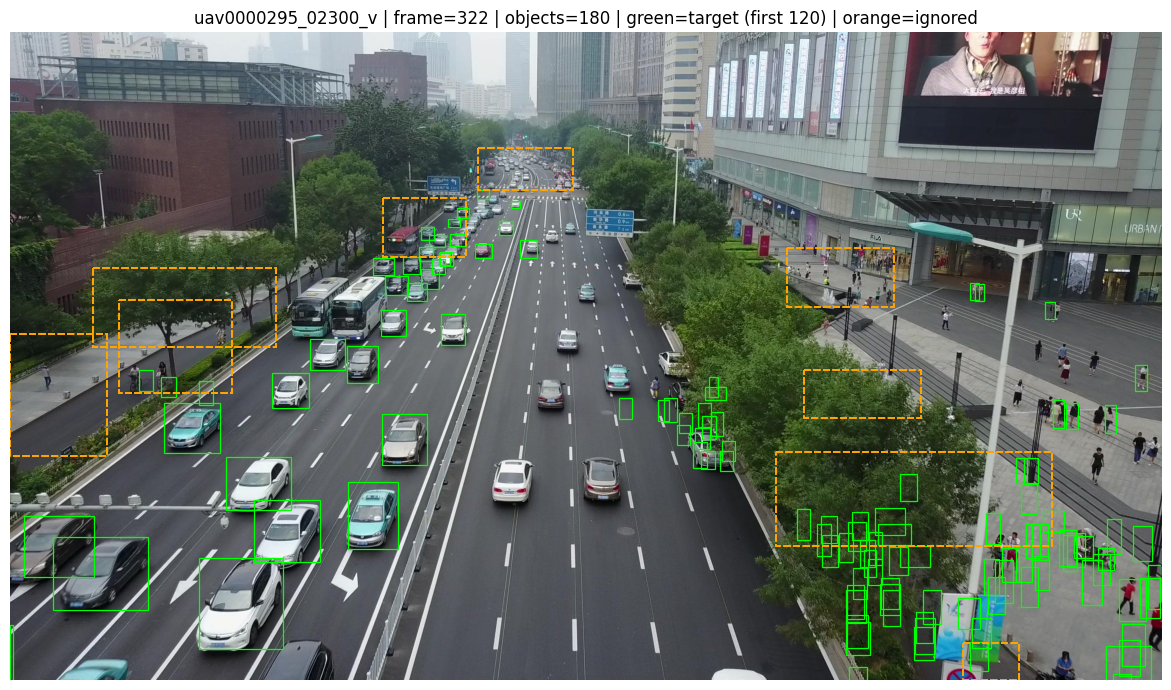

In [20]:
def resolve_image_path(row):
    file_name = Path(str(row['file_name']))
    split = str(row['split'])
    candidates = [
        file_name if file_name.is_absolute() else ROOT / file_name,
        ROOT / split / file_name,
        ROOT / split / 'images' / file_name,
    ]
    for candidate in candidates:
        if candidate.is_file():
            return candidate
    return None


def show_frame(row, max_target_boxes=120):
    path = resolve_image_path(row)
    if path is None:
        print(f"Image path not found for {row['image_uid']}: {row['file_name']}")
        return
    with Image.open(path) as im:
        image = im.convert('RGB')
    fig, ax = plt.subplots(figsize=(13, 7))
    ax.imshow(image)
    gt = target_df.loc[target_df['image_uid'].eq(row['image_uid'])]
    ign = annotations_df.loc[
        annotations_df['image_uid'].eq(row['image_uid']) & annotations_df['iscrowd'].eq(1)
    ]
    for _, b in gt.head(max_target_boxes).iterrows():
        ax.add_patch(Rectangle((b['x'], b['y']), b['box_w'], b['box_h'],
                               fill=False, linewidth=.9, edgecolor='lime'))
    for _, b in ign.iterrows():
        if b['valid_bbox']:
            ax.add_patch(Rectangle((b['x'], b['y']), b['box_w'], b['box_h'],
                                   fill=False, linewidth=1.3, edgecolor='orange', linestyle='--'))
    ax.set(title=f"{row['clip']} | frame={row['frame_id']} | objects={row['n_objects']} "
           f"| green=target (first {max_target_boxes}) | orange=ignored")
    ax.axis('off')
    finish_plot(f"sample_{row['clip']}_{row['original_image_id']}.png")

train_frames = frames_df.loc[frames_df['split'].eq('train')].sort_values('n_objects')
chosen_frames = pd.concat([
    train_frames.head(1),
    train_frames.iloc[[len(train_frames)//2]],
    train_frames.tail(1)
]).drop_duplicates('image_uid')
for _, row in chosen_frames.iterrows():
    show_frame(row)

Перший показаний train-кадр має 0 цільових boxes, типовий — 43, найщільніший — 180. У щільному кадрі візуально видно багато малих і частково перекритих об'єктів; ignored regions позначені помаранчевими контурами. Це узгоджується зі статистикою щільності, але три приклади не є репрезентативним доказом для всього датасету.


### 9.1. Додаткове дослідження: occlusion та truncation у цільових класах

Опис Kaggle окремо згадує частково перекриті об'єкти. У COCO JSON для кожної target annotation доступні occlusion і truncation. Можемо оцінити, які класи частіше мають ненульові коди та чи є різниця для small boxes. Це може підказати, які failure cases шукати після навчання.

In [31]:
audit_targets = target_df.loc[target_df['split'].eq('train')].copy()
for field in ['occlusion', 'truncation']:
    audit_targets[field] = pd.to_numeric(audit_targets[field], errors='coerce')

occlusion_by_class = audit_targets.groupby('class_name').agg(
    n_boxes=('image_uid', 'size'),
    occlusion_known_pct=('occlusion',lambda s: 100*s.notna().mean()),
    occlusion_nonzero_pct=('occlusion',lambda s: 100*(s.dropna()>0).mean() if s.notna().any() else np.nan),
    truncation_nonzero_pct=('truncation',lambda s: 100*(s.dropna()>0).mean() if s.notna().any() else np.nan)
).reindex(CLASS_ORDER)
display(occlusion_by_class.round(2))
print('Occlusion codes among annotated train targets:')
display(audit_targets['occlusion'].value_counts(dropna=False).sort_index())
print('Fraction of nonzero occlusion codes by COCO box size:')
display(audit_targets.groupby('size_group', observed=True)['occlusion']
        .agg(lambda s: round(100*(s.dropna()>0).mean(),2) if s.notna().any() else np.nan))

,n_boxes,occlusion_known_pct,occlusion_nonzero_pct,truncation_nonzero_pct
class_name,,,,
person,328701,100.0,45.89,1.96
bicycle,40255,100.0,53.52,0.84
car,505301,100.0,42.99,5.70
van,46940,100.0,42.86,4.15
truck,30498,100.0,64.69,11.20
tricycle,41349,100.0,59.13,4.61
bus,9653,100.0,44.07,13.77
motor,102819,100.0,45.28,3.15


Occlusion codes among annotated train targets:


occlusion
0.0    600789
1.0    445799
2.0     58928
Name: count, dtype: int64

Fraction of nonzero occlusion codes by COCO box size:


size_group
small     34.12
medium    50.96
large     41.39
Name: occlusion, dtype: float64

Ненульові позначки occlusion поширені, найвищу частку ненульового truncation мають bus (13,77%) і truck (11,20%). За розміром box позначений occlusion зустрічається у 34,12% small, 50,96% medium та 41,39% large об'єктів. Це підказує аналізувати помилки не лише за класом чи розміром, а й за occlusion / truncation: наприклад, порівняти кількість пропущених частково перекритих об'єктів з не перекритими. Водночас частка occlusion не дорівнює частці помилок: визначити, чи справді ці умови погіршують Faster R-CNN, можна лише після оцінювання predictions.

## 10. Додатковий EDA

clip містить послідовність кадрів; кількість видимих об'єктів змінюється з часом. Така структура потенційно корисна для temporal post-processing.



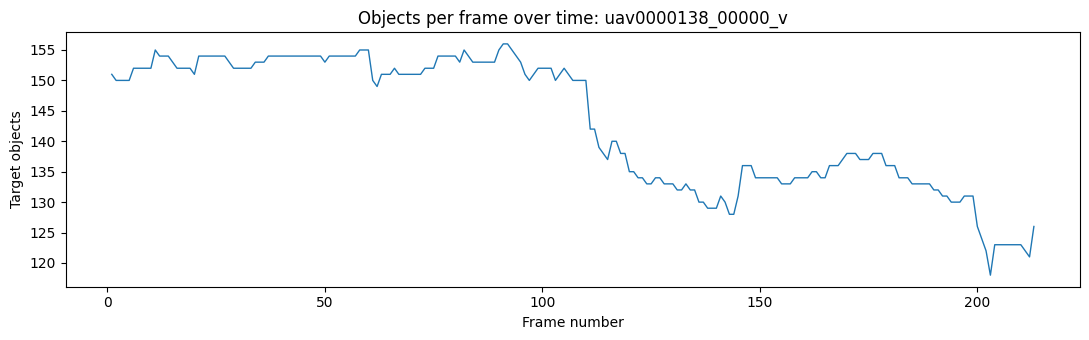

Track IDs present in target annotations: 1219648 of 1219648


In [32]:
# один найщільніший train clip.
clip_choice = (clip_stats.loc[clip_stats['split'].eq('train')]
               .sort_values('avg_objects', ascending=False).iloc[0]['clip'])
sequence_frames = frames_df.loc[
    frames_df['split'].eq('train') & frames_df['clip'].eq(clip_choice)
].copy()
# Якщо frame_id у COCO відсутній, використаємо номер із назви JPG.
frame_from_name = pd.to_numeric(
    sequence_frames['file_name'].map(lambda s: Path(str(s)).stem),
    errors='coerce'
)
sequence_frames['frame_number'] = pd.to_numeric(
    sequence_frames['frame_id'], errors='coerce'
).fillna(pd.Series(frame_from_name.values, index=sequence_frames.index))
sequence_frames = sequence_frames.sort_values('frame_number')

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(sequence_frames['frame_number'], sequence_frames['n_objects'], linewidth=1)
ax.set(title=f'Objects per frame over time: {clip_choice}',
       xlabel='Frame number', ylabel='Target objects')
finish_plot('optional_temporal_density.png')

print('Track IDs present in target annotations:',
      int(target_df['track_id'].notna().sum()), 'of', len(target_df))

Для найбільш щільного train clip uav0000138_00000_v кількість об'єктів протягом приблизно 213 кадрів спочатку тримається біля 150, а потім зменшується приблизно до 120–135. У всіх 1 219 648 target annotations поле track_id не порожнє.

## 11. Підсумок EDA

| Спостереження з поточного запуску | Гіпотеза / наступний тест (не доведений результат) |
|---|---|
| `car` 45,71% у train, `person` 29,73%; `bus` лише 0,87%; val має іншу суміш класів | Порівнювати **per-class AP** і помилки в різних clips; лише за потреби перевіряти class-aware sampling/augmentation |
| 24,91% train boxes — COCO-small; серед `person` 39,49% small | Порівняти **input resolution** та **anchor scales / aspect ratios**; контролювати **AP_small**, VRAM і speed |
| **Resizing simulation:** при short side 640 / 800 / 1024 частка boxes зі стороною <16 px — **28,12% / 19,52% / 12,35%** | Перевірити насамперед **800 vs 1024** у Faster R-CNN. Вищий resolution зберігає деталі, але його вплив на mAP і витрати ще невідомий |
| Медіана 43 об'єкти/кадр, P99 = 142, max = 180 | Дослідити **RPN proposal limits / detections_per_img / NMS**; кількість GT не дорівнює оптимальній кількості proposals |
| Clips різняться за щільністю, розмірами та складом класів | Зберегти split за `clip`; для додаткової CV застосувати **GroupKFold**, а не random frame split |
| Роздільності train / val / test відрізняються | Зберігати aspect ratio під час resizing; масштабувати boxes і повертати predictions до початкових координат |
| 542 704 ignored annotations (`iscrowd=1`), invalid target boxes — 0; **ignored є на 74,75% train-кадрів і 50,39% val-кадрів** | Реалізувати та перевірити **don't-care handling**; не вважати ignored області звичайним background. Кількість областей не дорівнює їхній площі |
| Ненульовий `occlusion` у **64,69% truck**, **59,13% tricycle** та **53,52% bicycle**; `truncation` — **13,77% bus** і **11,20% truck** | Після baseline перевірити **failure cases** за класами та occlusion / truncation, а не тільки за розміром об'єктів |
| У всіх 1 219 648 target annotations є `track_id`; щільність змінюється вздовж clip | Можливий напрям **Temporal bonus**: трекінг або temporal post-processing, але потрібен окремий експеримент з оцінюванням виграшу |

**Найближчі кроки:**
- для Faster R-CNN зробити спільний baseline на незмінному sequence-level validation,
- окремо порівняти input resolution, anchors / RPN settings і обробку ignored regions.
- звітувати mAP, AP50, AP_small, per-class AP та inference speed. (Змінювати перевіряти по одній, щоб можна було пояснити їхній внесок.)